In [103]:
import matplotlib.pyplot as plt
import numpy as np
W_MTOW = 412000
cg_MTOW = 0.53*203.75
cg_tanks = {
    "1": (105.265, -11.012),
    "2": (141.026, -10.158),
    "3": (141.026,  10.158),
    "4": (105.265,  11.012),
    "5": (115.190, -13.533),
    "5a": (138.678, -29.650),
    "6": (131.041, -10.649),
    "7": (129.443,  16.879),
    "7a": (138.678,  29.650),
    "8": (112.474,   8.341),
    "9": (82.956,   0.000),
    "10": (96.571,  0.000),
    "11": (159.195, 0.000),
}
W_tanks = {
    "1": 4240.0*2.2046,
    "2": 4620.0*2.2046,
    "3": 4620.0*2.2046,
    "4": 4240.0*2.2046,
    "5": 7270.0*2.2046,
    "5a": 2250.0*2.2046,
    "6": 11700.0*2.2046,
    "7": 7480.0*2.2046,
    "7a": 2250.0*2.2046,
    "8": 12970.0*2.2046,
    "9": 11210.0*2.2046,
    "10": 12060.0*2.2046,
    "11": 10520.0*2.2046,
}
W_tanks_total = 0
for i in W_tanks:
    W_tanks_total += W_tanks[i]
W_ZFW = W_MTOW-W_tanks_total
print(W_tanks_total)
print(cg_MTOW)
for i in W_tanks:
    print(W_tanks[i]/W_tanks_total)

210384.978
107.98750000000001
0.044430472597715605
0.0484124489154354
0.0484124489154354
0.044430472597715605
0.07618149428900765
0.02357749135491984
0.12260295504558315
0.07838206014880017
0.02357749135491984
0.13591113905480456
0.11746830137273395
0.12637535366237032
0.11023787069055853


In [104]:
cg_ZFW = cg_MTOW
for i in W_tanks:
    cg_ZFW -= W_tanks[i]*cg_tanks[i][0]/W_MTOW
cg_ZFW=cg_ZFW*W_MTOW/W_ZFW
print(cg_ZFW)
print(cg_ZFW/203.75)

96.16185964412908
0.47196004733314884


In [122]:
W_tanks_calc = W_tanks.copy()
scheme75a = {"1": 1, "2": 1,"3": 1,"4": 1,
             "11": 1,"5a": 1,"7a": 1,"6": 1,"7": 1,"5": 1,"8": 1,"10": 0,"9": 0,}
scheme75f = {"1": 1, "2": 1,"3": 1,"4": 1,
             "11": 0,"5a": 0,"7a": 0,"6": 0.55,"7": 0.55,"5": 1,"8": 1,"10": 1,"9": 1,}
scheme55a = {"1": 1, "2": 1,"3": 1,"4": 1,
             "11": 1,"5a": 1,"7a": 1,"6": 1,"7": 1,"5": 0,"8": 0,"10": 0,"9": 0,}
scheme55f = {"1": 1, "2": 1,"3": 1,"4": 1,
             "11": 0,"5a": 0,"7a": 0,"6": 0,"7": 0,"5": 0.55,"8": 0.55,"10": 1,"9": 1,}
scheme45a = {"1": 1, "2": 1,"3": 1,"4": 1,
             "11": 1,"5a": 1,"7a": 1,"6": 0.55,"7": 0.55,"5": 0,"8": 0,"10": 0,"9": 0,}
scheme45f = {"1": 1, "2": 1,"3": 1,"4": 1,
             "11": 0,"5a": 0,"7a": 0,"6": 0,"7": 0,"5": 0.1,"8": 0.1,"10": 1,"9": 1,}
scheme15 = {"1": 0.8, "2": 0.8,"3": 0.8,"4": 0.8,
             "11": 0,"5a": 0,"7a": 0,"6": 0,"7": 0,"5": 0,"8": 0,"10": 0,"9": 0,}
scheme_calc = scheme15

for i in W_tanks_calc:
    W_tanks_calc[i] = W_tanks_calc[i]*scheme_calc[i]
W_tanks_total_calc = 0
for i in W_tanks_calc:
    W_tanks_total_calc += W_tanks_calc[i]
print(W_tanks_total_calc/W_tanks_total)
cg_calc = cg_ZFW*W_ZFW/(W_ZFW+W_tanks_total_calc)
for i in W_tanks_calc:
    cg_calc += W_tanks_calc[i]*cg_tanks[i][0]/(W_ZFW+W_tanks_total_calc)
print(cg_calc)
print(cg_calc/203.75)

0.14854867442104158
99.88617068206285
0.4902388745131919


0.53


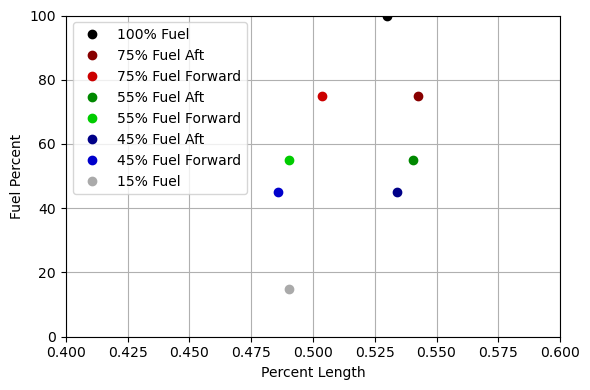

In [152]:
p100 = cg_MTOW/203.75
print(cg_MTOW/203.75)
p75f = 0.5038289162833961
p75a = 0.5425476020353474
p55f = 0.49045657274466925
p55a = 0.5405344929014738
p45f = 0.4859623083572693
p45a = 0.5341575116041882
p15 = 0.4902388745131919
plt.figure(figsize=(6,4))
plt.plot(p100, 100, 'o', label="100% Fuel", color="#000000")
plt.plot(p75a, 75, 'o', label="75% Fuel Aft", color="#880000")
plt.plot(p75f, 75, 'o', label="75% Fuel Forward", color="#CC0000")
plt.plot(p55a, 55, 'o', label="55% Fuel Aft", color="#008800")
plt.plot(p55f, 55, 'o', label="55% Fuel Forward", color="#00CC00")
plt.plot(p45a, 45, 'o', label="45% Fuel Aft", color="#000088")
plt.plot(p45f, 45, 'o', label="45% Fuel Forward", color="#0000CC")
plt.plot(p15, 15, 'o', label="15% Fuel", color="#AAAAAA")
plt.legend()
plt.xlim(0.4, 0.6)
plt.ylim(0, 100)
plt.xlabel('Percent Length')
plt.ylabel('Fuel Percent')
#plt.yticks([])
plt.grid(True)
plt.tight_layout()
plt.show()